# **Set Up**
1. Necessary imports that will be used throughout the entire file.
2. Read the data set from **Kaggle**. (CSV file)

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# webtoon_originals_en.csv
df = pd.read_csv("webtoon_originals_en.csv", na_filter = False)

# **Looking at the Table**
1. Use `shape()` and `columns()` to get a feel for this dataset's structure.
--> 2227 rows [entries for webtoon], 12 columns [metrics]
2. Modify the data frame to include columns we want. "ratings" is all 0.0 because the API used by this dataset
is not fetching properly.
3. Display the first 5 rows using `head(5)`

In [52]:
print(df.shape)
print(df.columns)

# Removing the title_id, weekdays, rating, and synopsis columns.
df = df[["title", "genre", "authors", "length", "subscribers", "views", "likes", "status"]]

# display(df.sort_values(by="views", ascending=False).head(5))
display(df.head(5))
print(df.shape)

(2277, 8)
Index(['title', 'genre', 'authors', 'length', 'subscribers', 'views', 'likes',
       'status'],
      dtype='str')


,title,genre,authors,length,subscribers,views,likes,status
0,The Grudge,ROMANCE,Kuaikan Comics,4,262,1529,46,ONGOING
1,Junk to King: I Am A Scavenger,ACTION,"Dong Yiffy,King,Youma Wenhua,BILIBILI COMICS",6,2840,19514,989,COMPLETED
2,Elixir of the Sun,ROMANCE,"one,Song Yi,Sung U Hyun,Solddam",3,2559,15181,782,COMPLETED
3,Deadman's Undecember,ACTION,FanFan Comic,9,1136,3263,278,ONGOING
4,24-Hour Rebirth Consultation Center,FANTASY,"Yeseong,nokum,Cheong Ahan",4,9057,51487,3722,COMPLETED


(2277, 8)


# **Cleaning Data:**
Just to important checks to ensure the data is safe to work with.

1. Check for empty strings and duplicates.

In [38]:
df.info() # get the general info

print((df == "").sum()) # bc of na_filter = false, we need to check for empty strings.

print(df.duplicated().sum())

# df[["length", "subscribers", "views", "likes"]].describe()

<class 'pandas.DataFrame'>
RangeIndex: 2277 entries, 0 to 2276
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   title        2277 non-null   str  
 1   genre        2277 non-null   str  
 2   authors      2277 non-null   str  
 3   length       2277 non-null   int64
 4   subscribers  2277 non-null   int64
 5   views        2277 non-null   int64
 6   likes        2277 non-null   int64
 7   status       2277 non-null   str  
dtypes: int64(4), str(4)
memory usage: 142.4 KB
title          0
genre          0
authors        0
length         0
subscribers    0
views          0
likes          0
status         0
dtype: int64
0


# **GENRE**
1. How many unique genres / count of webtoons per genre in this dataset?
2. What are the genres with the highest and lowest engagement?

There are 17 unique genres in this dataset.


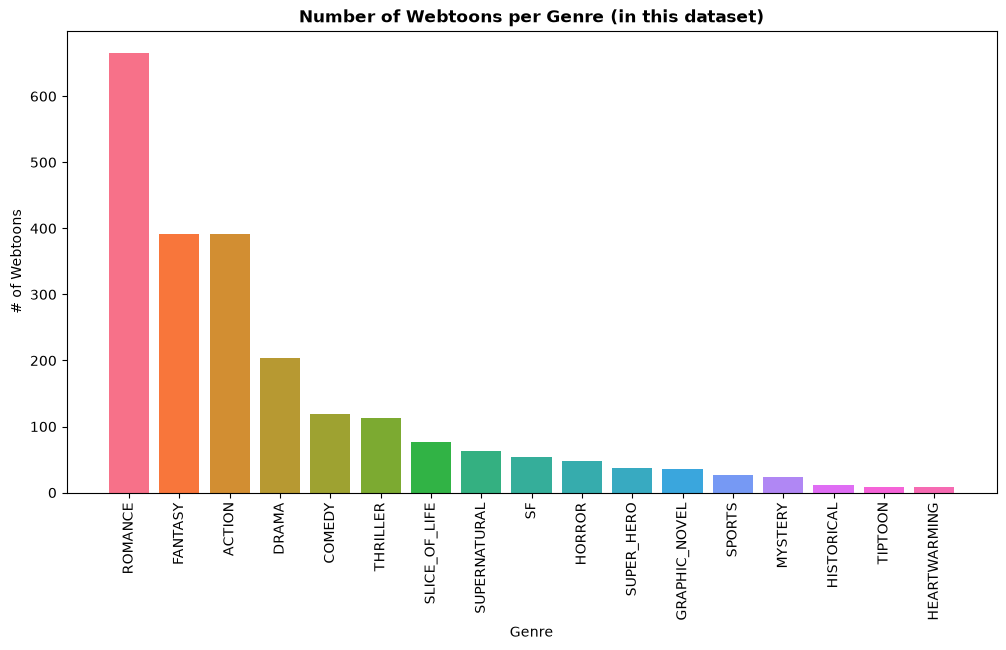

In [ ]:
# How many unique genres are there?
# How many number of each genre in the dataset?

print(f"There are {df['genre'].nunique()} unique genres in this dataset.")
genre_counts = df["genre"].value_counts()

# colors:
colors = sns.color_palette("husl", len(genre_counts))

# PLOT AS A BAR CHART :

plt.figure(figsize = (12,6))
plt.bar(x = genre_counts.index, height = genre_counts.values, color = colors)

# labeling / adjustments:
plt.xticks(rotation=90)
plt.title("Number of Webtoons per Genre (in this dataset)", fontweight = "bold")
plt.xlabel("Genre")
plt.ylabel("# of Webtoons")

plt.savefig("plots/num_genres.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()



genre
SLICE_OF_LIFE    5.752397e+07
SUPER_HERO       4.508982e+07
COMEDY           3.580672e+07
Name: views, dtype: float64

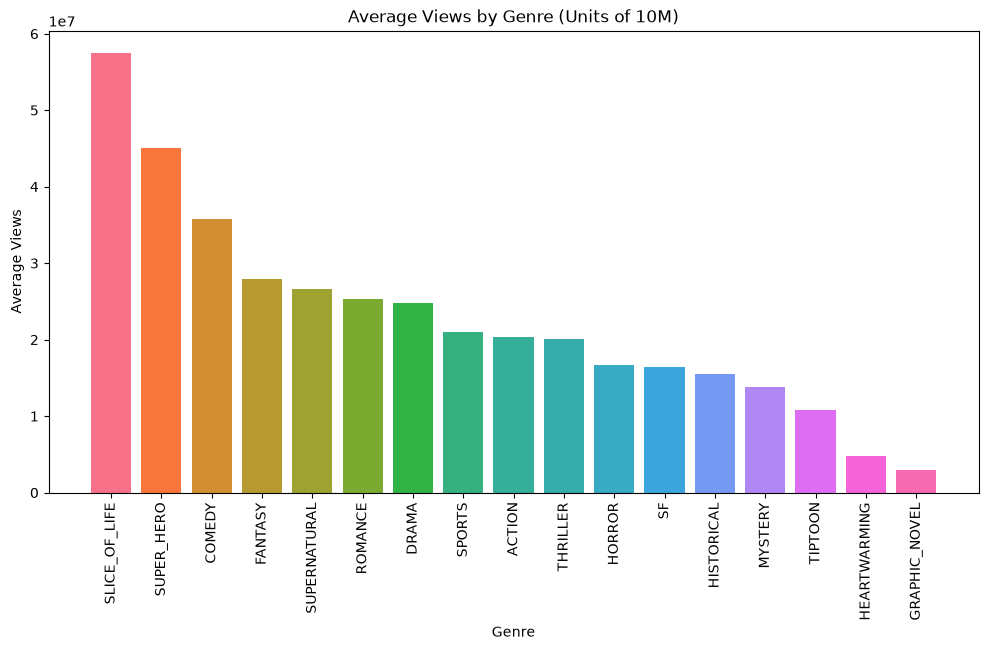

In [ ]:
# What is the average of views by Genre?

# Display Top 3 Genres with Highest Average Views sorted in Descending Order

avg_views = df.groupby("genre")["views"].mean().sort_values(ascending = False)
display(avg_views[0:3])

# Plot the Bar Chart :
plt.figure(figsize = (12,6))

# colors:
colors = sns.color_palette("husl", len(avg_views))

plt.bar(x=avg_views.index, height=avg_views.values, color = colors)
plt.title("Average Views by Genre (Units of 10M)")
plt.xlabel("Genre")
plt.ylabel("Average Views")
plt.xticks(rotation=90)

plt.savefig("plots/avg_views_genre.png", dpi=300, bbox_inches="tight", transparent=False) 
plt.show()

genre
SLICE_OF_LIFE    4.789276e+06
COMEDY           3.001405e+06
SUPER_HERO       2.477437e+06
Name: likes, dtype: float64

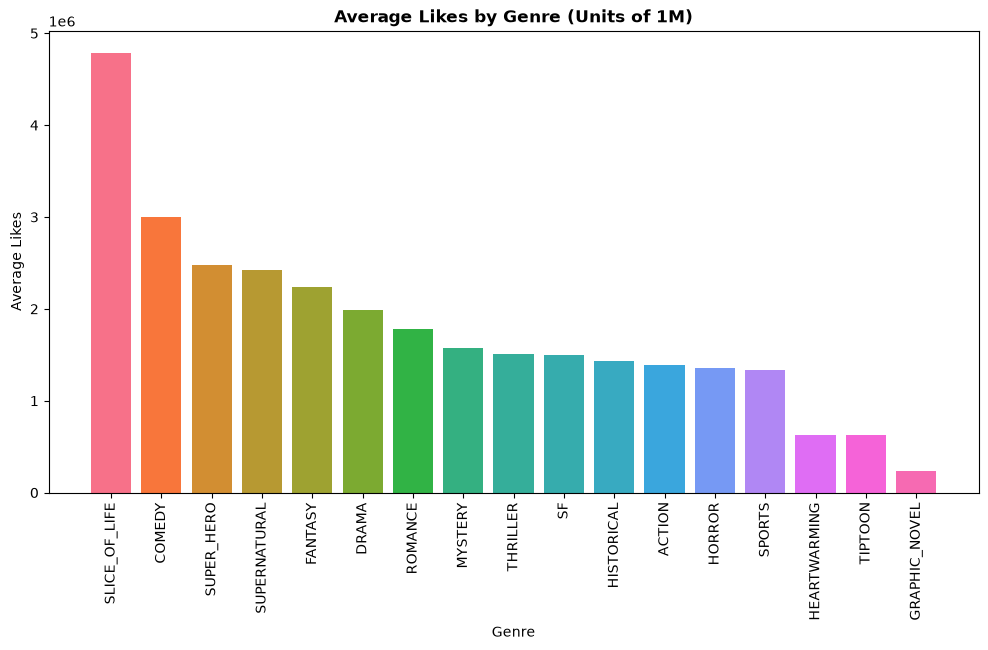

In [ ]:
# What is the average of likes by Genre?

# Display Top 3 Genres with Highest Average Likes sorted in Descending Order

avg_likes = df.groupby("genre")["likes"].mean().sort_values(ascending = False)
display(avg_likes[0:3])

# Plot the Bar Chart :
plt.figure(figsize = (12,6))

# colors:
colors = sns.color_palette("husl", len(avg_likes))

plt.bar(x=avg_likes.index, height=avg_likes.values, color=colors)
plt.title("Average Likes by Genre (Units of 1M)", fontweight = "bold")
plt.xlabel("Genre")
plt.ylabel("Average Likes")
plt.xticks(rotation=90)

plt.savefig("plots/avg_likes_genre.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()

# **View / Like Related Questions**
1. Rank by Views
2. Rank by Likes
3. Total distribution of Views (Plotly)

,title,genre,authors,subscribers,views,likes,status
2061,Lore Olympus,ROMANCE,Rachel Smythe,6649628,1427726818,72888685,COMPLETED
2140,unOrdinary,SUPER_HERO,uru-chan,6299250,1397987835,71369756,ONGOING
2246,Tower of God,FANTASY,SIU,4221200,1288045134,66332771,HIATUS
2103,Lookism,DRAMA,Taejun Pak,3847160,1071346830,59347796,ONGOING
2041,True Beauty,ROMANCE,Yaongyi,7545593,1036981207,55811728,COMPLETED
2116,My Giant Nerd Boyfriend,SLICE_OF_LIFE,fishball,2402091,856721498,79456119,ONGOING
2274,The God of High School,ACTION,Dragon j,2981789,799518634,31887388,COMPLETED
2112,I Love Yoo,DRAMA,Quimchee,4751323,645598010,40207660,ONGOING
1948,Down To Earth,ROMANCE,Pookie Senpai,4419082,619301663,28960248,HIATUS
2236,Bluechair,SLICE_OF_LIFE,Shen,1435565,604636242,51462556,COMPLETED


,title,genre,authors,subscribers,views,likes,status
0,The Grudge,ROMANCE,Kuaikan Comics,262,1529,46,ONGOING
112,The Amazing Spider-Man: Big Time,ACTION,Marvel,1006,1610,113,ONGOING
3,Deadman's Undecember,ACTION,FanFan Comic,1136,3263,278,ONGOING
2,Elixir of the Sun,ROMANCE,"one,Song Yi,Sung U Hyun,Solddam",2559,15181,782,COMPLETED
1,Junk to King: I Am A Scavenger,ACTION,"Dong Yiffy,King,Youma Wenhua,BILIBILI COMICS",2840,19514,989,COMPLETED
365,Vigilante 2,THRILLER,"kim kyusam,CRG",7329,24465,1265,COMPLETED
96,Taka,ACTION,IDW Publishing,5887,25221,3117,HIATUS
162,Star Wars™: The Legends of Luke Skywalker - Th...,SF,Lucasfilm Ltd.,5700,25379,2741,ONGOING
190,Stitch in Time,FANTASY,"Disney,Adriano Barone,Fabrizio Cosentino",5964,31792,2643,ONGOING
54,Devils' Crest,FANTASY,"REKI KAWAHARA,Takano Koroku,TO Moe",4663,34020,1327,ONGOING


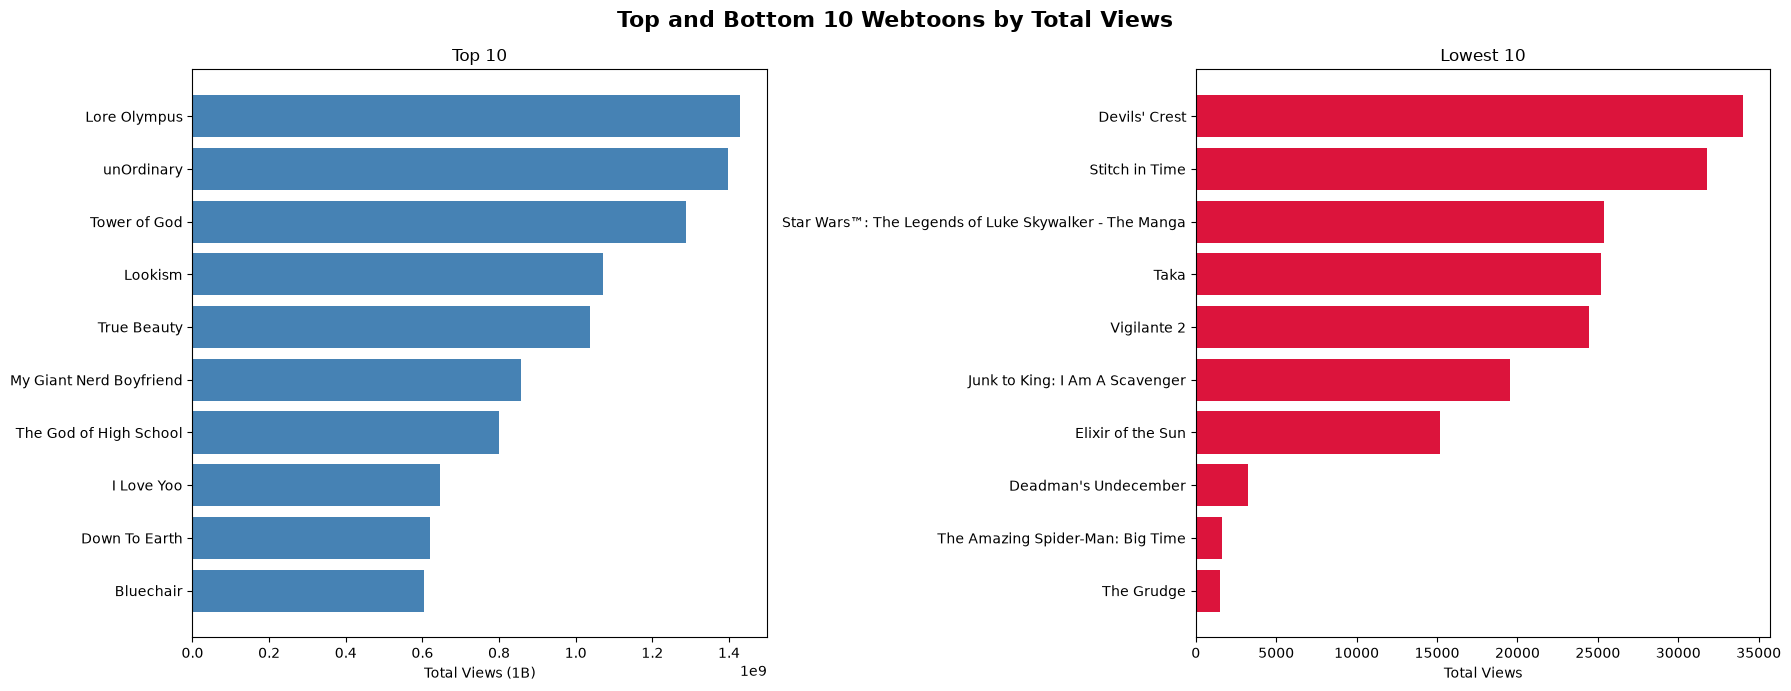

In [ ]:
# Top 10 Webtoons with Most Views

top_10 = df.sort_values(by = "views", ascending = False).head(10)
top_10 = top_10[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(top_10) 

# Top 10 Webtoons with Least Views

bottom_10 = df.sort_values(by = "views", ascending = True).head(10)
bottom_10 = bottom_10[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(bottom_10) 

# PLOT RANKINGS AS BAR CHARTS :
fig, ax = plt.subplots(1,2, figsize=(18,7)) # set up the figure

ax[0].barh(y = top_10["title"], width = top_10["views"], color = "steelblue")
ax[1].barh(y = bottom_10["title"], width = bottom_10["views"], color = "crimson")

# MODIFICATIONS :
fig.suptitle("Top and Bottom 10 Webtoons by Total Views", fontsize = 16, fontweight= "bold")

ax[0].invert_yaxis()
ax[0].set_title("Top 10")
ax[0].set_xlabel("Total Views (1B)")

ax[1].set_title("Lowest 10")
ax[1].set_xlabel("Total Views")


plt.tight_layout() # helps with automatically adjusting spacing.

plt.savefig("plots/views_ranked.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()



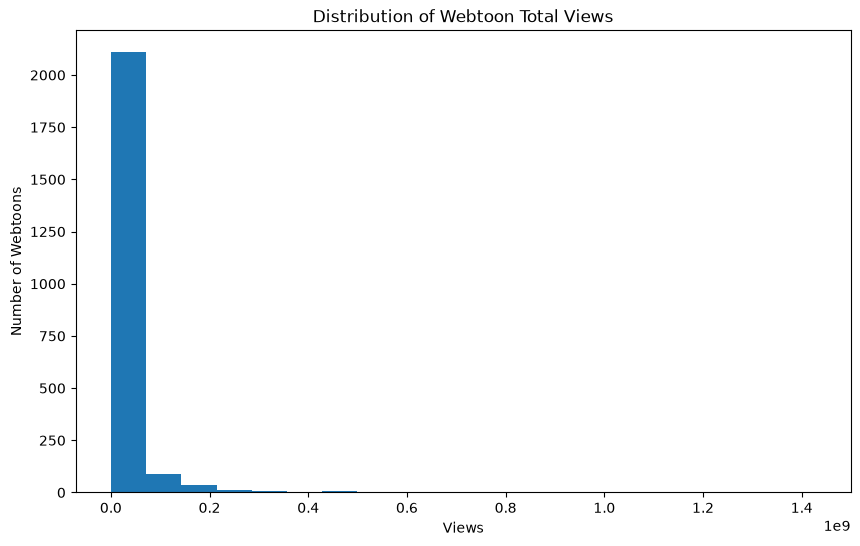

In [43]:
# Histogram of Views (count # of webtoons by bins of views)

plt.figure(figsize=(10, 6))

plt.hist(x = df["views"], bins=20)

plt.title("Distribution of Webtoon Total Views")
plt.xlabel("Views")
plt.ylabel("Number of Webtoons")

plt.show()

In [44]:
# make a new data frame with a views_ranked column :
views_ranked = df.sort_values(by="views", ascending=False)
views_ranked["rank"] = range(1, len(views_ranked) + 1)
display(views_ranked.head(5))

# Plotly intertactive graph : (x: rank, y: total views)
fig = px.scatter(views_ranked, x="rank", y="views", color="genre",
                 hover_name = "title", hover_data = ["genre", "likes", "subscribers"],
                 title="Total Views Across All Webtoons", template="plotly_white",
                 width=1200, height=650)
fig.show()

,title,genre,authors,length,subscribers,views,likes,status,rank
2061,Lore Olympus,ROMANCE,Rachel Smythe,9,6649628,1427726818,72888685,COMPLETED,1
2140,unOrdinary,SUPER_HERO,uru-chan,413,6299250,1397987835,71369756,ONGOING,2
2246,Tower of God,FANTASY,SIU,652,4221200,1288045134,66332771,HIATUS,3
2103,Lookism,DRAMA,Taejun Pak,621,3847160,1071346830,59347796,ONGOING,4
2041,True Beauty,ROMANCE,Yaongyi,8,7545593,1036981207,55811728,COMPLETED,5


,title,genre,authors,subscribers,views,likes,status
2116,My Giant Nerd Boyfriend,SLICE_OF_LIFE,fishball,2402091,856721498,79456119,ONGOING
2061,Lore Olympus,ROMANCE,Rachel Smythe,6649628,1427726818,72888685,COMPLETED
2140,unOrdinary,SUPER_HERO,uru-chan,6299250,1397987835,71369756,ONGOING
2246,Tower of God,FANTASY,SIU,4221200,1288045134,66332771,HIATUS
2103,Lookism,DRAMA,Taejun Pak,3847160,1071346830,59347796,ONGOING
2041,True Beauty,ROMANCE,Yaongyi,7545593,1036981207,55811728,COMPLETED
2236,Bluechair,SLICE_OF_LIFE,Shen,1435565,604636242,51462556,COMPLETED
1903,Omniscient Reader,ACTION,"singNsong,UMI,Sleepy-C",4506004,602395522,44496697,HIATUS
1906,The Remarried Empress,FANTASY,"SUMPUL,HereLee,Alphatart",4595316,572865714,44301821,COMPLETED
2112,I Love Yoo,DRAMA,Quimchee,4751323,645598010,40207660,ONGOING


,title,genre,authors,subscribers,views,likes,status
0,The Grudge,ROMANCE,Kuaikan Comics,262,1529,46,ONGOING
112,The Amazing Spider-Man: Big Time,ACTION,Marvel,1006,1610,113,ONGOING
3,Deadman's Undecember,ACTION,FanFan Comic,1136,3263,278,ONGOING
2,Elixir of the Sun,ROMANCE,"one,Song Yi,Sung U Hyun,Solddam",2559,15181,782,COMPLETED
14,Playboy Helper,ROMANCE,"Monacha,SsM SlitheringMe",5493,44929,855,ONGOING
1,Junk to King: I Am A Scavenger,ACTION,"Dong Yiffy,King,Youma Wenhua,BILIBILI COMICS",2840,19514,989,COMPLETED
208,Begrudgingly Yours,ROMANCE,"2sha,dyang,gongnyong,the perfect mismatch",8099,40510,1181,COMPLETED
365,Vigilante 2,THRILLER,"kim kyusam,CRG",7329,24465,1265,COMPLETED
145,Golden Time,ROMANCE,"Hee Won,Ryu Hyang",7919,35690,1319,ONGOING
54,Devils' Crest,FANTASY,"REKI KAWAHARA,Takano Koroku,TO Moe",4663,34020,1327,ONGOING


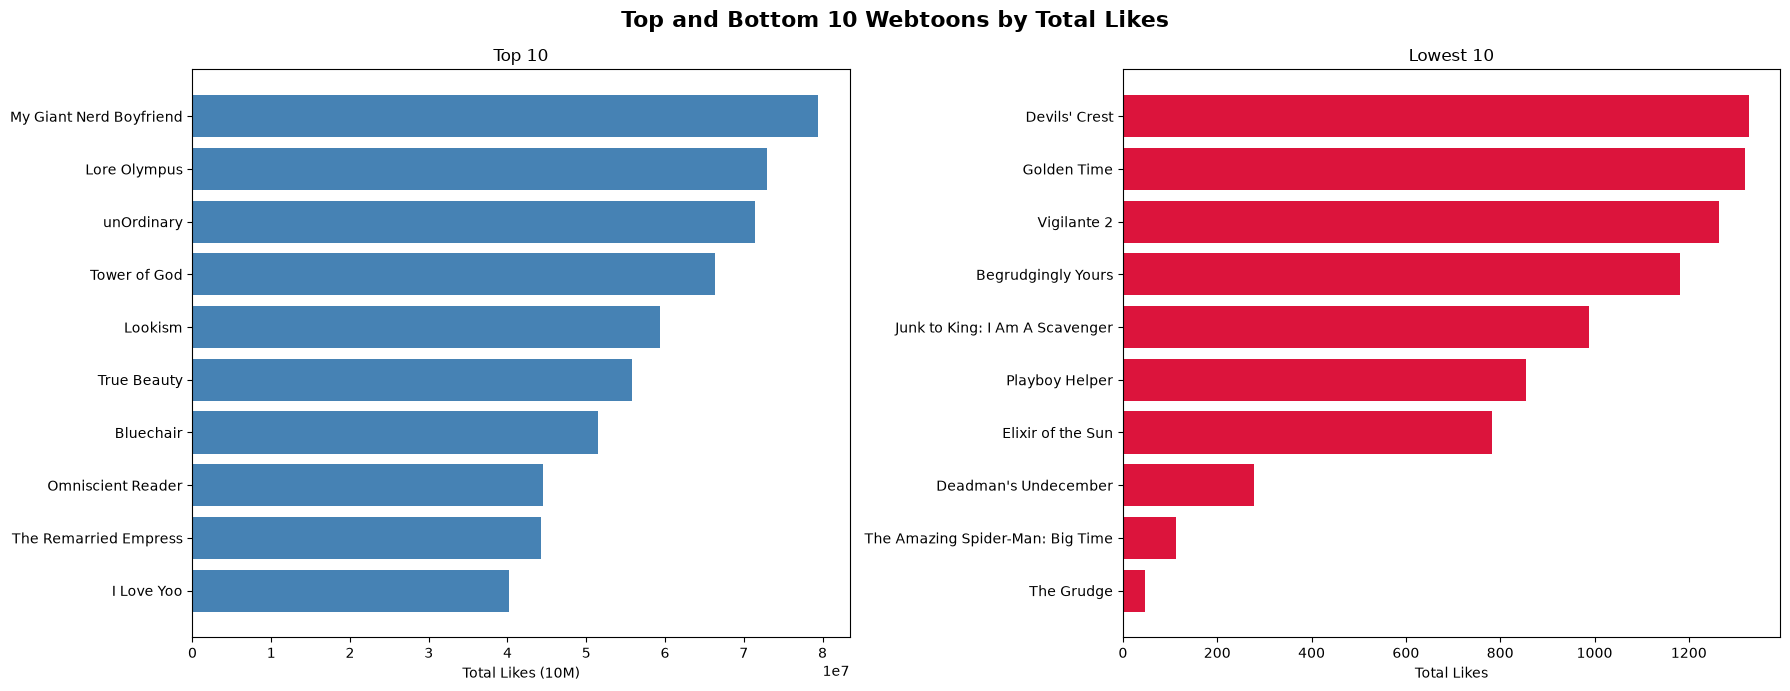

In [ ]:
# Likes :

# Top 10 Webtoons with Most Likes

top_10_likes = df.sort_values(by = "likes", ascending = False).head(10)
top_10_likes = top_10_likes[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(top_10_likes) 

# Top 10 Webtoons with Least Likes

bottom_10_likes = df.sort_values(by = "likes", ascending = True).head(10)
bottom_10_likes = bottom_10_likes[["title", "genre", "authors", "subscribers", "views", "likes", "status"]]
display(bottom_10_likes) 

# PLOT RANKINGS AS BAR CHARTS :
fig, ax = plt.subplots(1,2, figsize=(18,7)) # set up the figure

ax[0].barh(y = top_10_likes["title"], width = top_10_likes["likes"], color = "steelblue")
ax[1].barh(y = bottom_10_likes["title"], width = bottom_10_likes["likes"], color = "crimson")

# MODIFICATIONS :
fig.suptitle("Top and Bottom 10 Webtoons by Total Likes", fontsize = 16, fontweight= "bold")

ax[0].invert_yaxis()
ax[0].set_title("Top 10")
ax[0].set_xlabel("Total Likes (10M)")

ax[1].set_title("Lowest 10")
ax[1].set_xlabel("Total Likes")

plt.tight_layout() # helps with automatically adjusting spacing.

plt.savefig("plots/likes_ranked.png", dpi=300, bbox_inches="tight", transparent=False)
plt.show()



# **Correlations**
Is there a relationship between total views and likes?
- Generally, there is a strong relationship between views and likes. As views increases, the likes tend to increase as well.

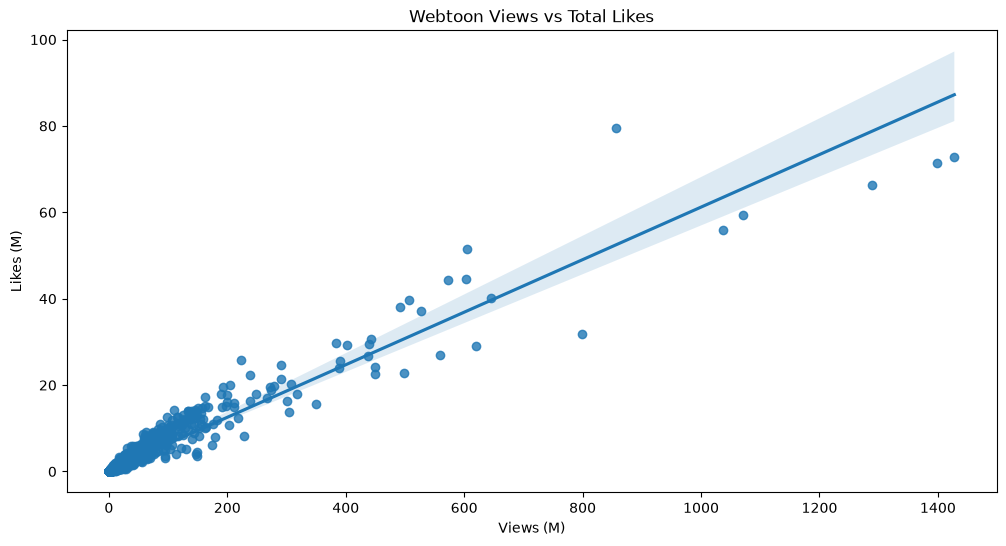

0.9614245725123912


In [46]:
# Scatter Plot by Views:

plt.figure(figsize = (12,6))

sns.regplot(x=df["views"] / 1e6, y=df["likes"] / 1e6) # 

plt.title("Webtoon Views vs Total Likes")
plt.xlabel("Views (M)")
plt.ylabel("Likes (M)")
plt.show()

# correlation factor between views and likes
# [-1 1] scale, lower: strong negative, higher: strong positive
# 0.96 - very strong positively correlated.
correlation = df["views"].corr(df["likes"])
print(correlation)



**Is there any correlations with subscribers?**
- Generally, there is a high relationship between subscribers and likes/views.

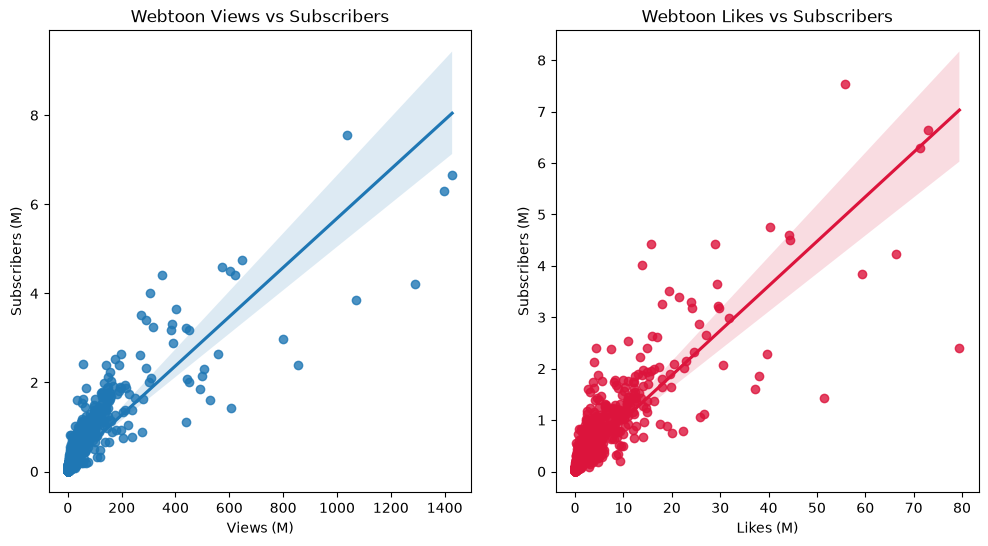

0.868353339381515
0.8635335897564568


In [47]:
# Scatter Plot for Views by Subscribers

fig, ax = plt.subplots(1,2, figsize = (12,6))

sns.regplot(x=df["views"] / 1e6, y=df["subscribers"] / 1e6, ax = ax[0]) 

ax[0].set_title("Webtoon Views vs Subscribers")
ax[0].set_xlabel("Views (M)")
ax[0].set_ylabel("Subscribers (M)")

sns.regplot(x=df["likes"] / 1e6, y=df["subscribers"] / 1e6, ax = ax[1], color="crimson") 

ax[1].set_title("Webtoon Likes vs Subscribers")
ax[1].set_xlabel("Likes (M)")
ax[1].set_ylabel("Subscribers (M)")

plt.show()

# correlation factor between views and likes
# [-1 1] scale, lower: strong negative, higher: strong positive
# 0.96 - very strong positively correlated.
correlation1 = df["views"].corr(df["subscribers"])
correlation2 = df["likes"].corr(df["subscribers"])

print(correlation1)
print(correlation2)


**Is there any correlation with webtoon length?**
- Generally, there is a moderate relationship between length and views/likes

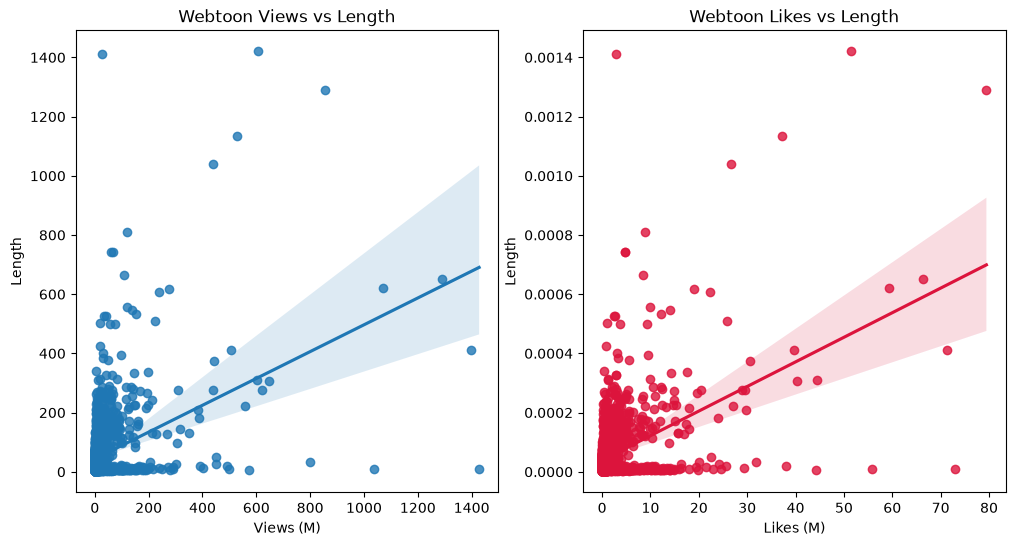

0.40079259387229565
0.4649059287494233


In [48]:
# Scatter Plot for Views by Length

fig, ax = plt.subplots(1,2, figsize = (12,6))

sns.regplot(x=df["views"] / 1e6, y=df["length"], ax = ax[0]) 

ax[0].set_title("Webtoon Views vs Length")
ax[0].set_xlabel("Views (M)")
ax[0].set_ylabel("Length")

sns.regplot(x=df["likes"] / 1e6, y=df["length"] / 1e6, ax = ax[1], color="crimson") 

ax[1].set_title("Webtoon Likes vs Length")
ax[1].set_xlabel("Likes (M)")
ax[1].set_ylabel("Length")

plt.show()

# correlation factor between views and likes
# [-1 1] scale, lower: strong negative, higher: strong positive
# 0.96 - very strong positively correlated.
correlation1 = df["views"].corr(df["length"])
correlation2 = df["likes"].corr(df["length"])

print(correlation1)
print(correlation2)


# **Status Analysis**
3 Categories:
- Ongoing
- Completed
- Hiatus


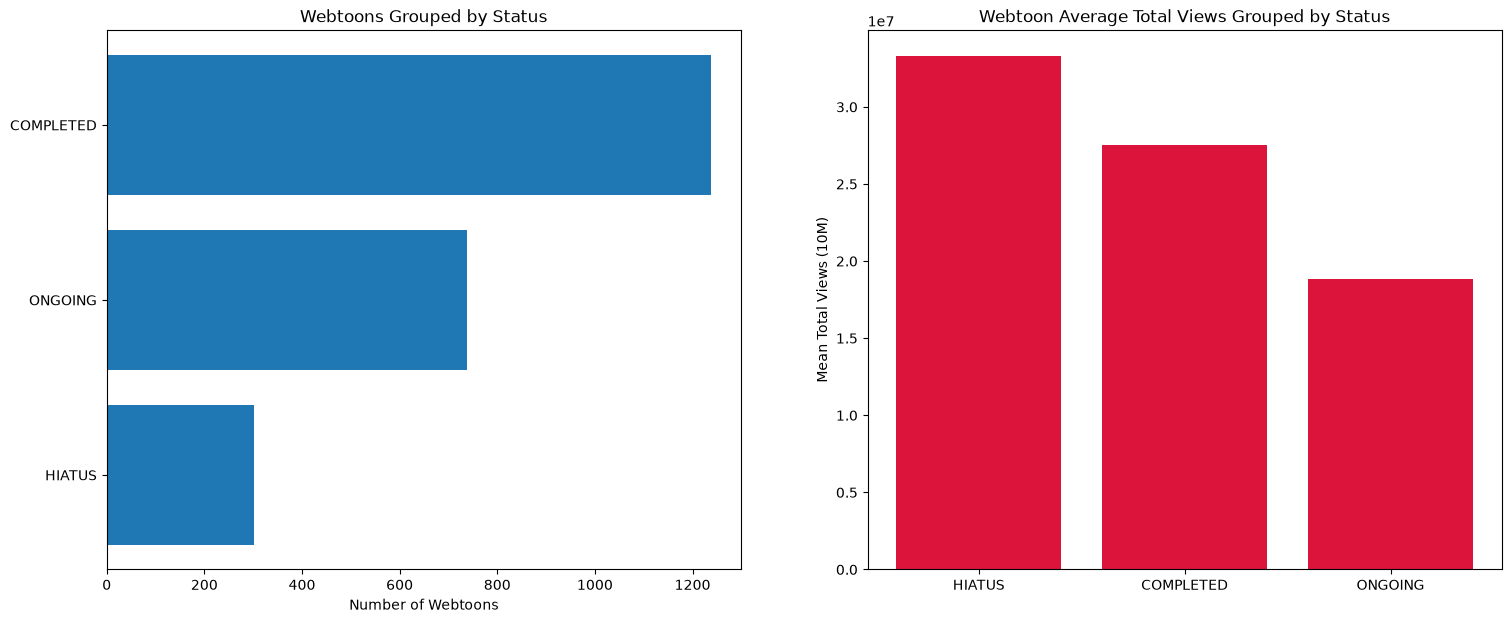

In [49]:
# Average Views & Likes by Status :

status_vals = df["status"].value_counts()

status_mean = df.groupby("status")["views"].mean().sort_values(ascending=False)

fig, ax = plt.subplots(1,2, figsize=(18,7))

# first graph : frequency 
ax[0].barh(y = status_vals.index, width = status_vals.values)
ax[0].set_title("Webtoons Grouped by Status")
ax[0].set_xlabel("Number of Webtoons")
ax[0].invert_yaxis()

# second graph : mean

ax[1].bar(x = status_mean.index, height = status_mean.values, color = "crimson")
ax[1].set_title("Webtoon Average Total Views Grouped by Status")
ax[1].set_ylabel("Mean Total Views (10M)")


plt.show()

# **Like / View Ratio**

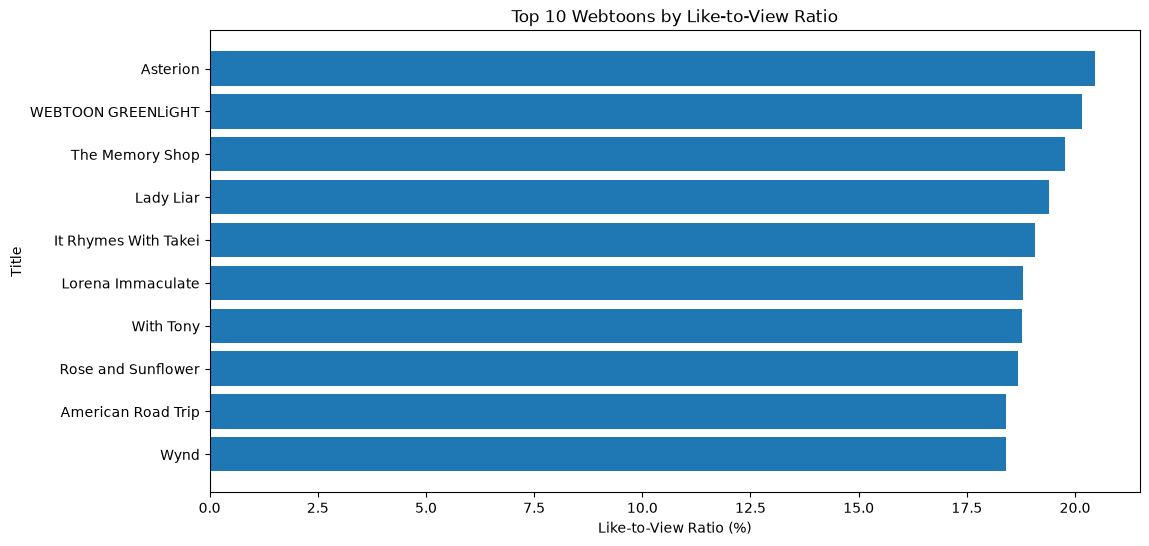

In [50]:
lvr_df = df[["title", "genre", "views", "likes"]] # create a copy of the df, but with only the specified columns
lvr_df["lv_percent"] = lvr_df["likes"] / lvr_df["views"] * 100 # create a new column like-value-percent

lvr_df = lvr_df.sort_values(by = "lv_percent", ascending = False) # sort it by descending order according to like-value-percent
top10_percent = lvr_df.head(10) # get the top 10

# BARH PLOT : 
plt.figure(figsize = (12,6))
plt.barh(y = top10_percent["title"], width = top10_percent["lv_percent"])
plt.gca().invert_yaxis()

plt.title("Top 10 Webtoons by Like-to-View Ratio")
plt.xlabel("Like-to-View Ratio (%)")
plt.ylabel("Title")

plt.show()


**Finding Underrated Webtoons:**
- I am looking for webtoons specifically below the median that have the highest like to view ratio.

4908893.0


,title,genre,views,likes,lv_percent
1862,Asterion,DRAMA,2270753,464804,20.469157
844,The Memory Shop,HEARTWARMING,1005767,198873,19.773268
197,It Rhymes With Takei,TIPTOON,94790,18071,19.064247
1089,Lorena Immaculate,HORROR,798690,150059,18.788141
1458,With Tony,SLICE_OF_LIFE,485411,91112,18.770073
1195,Rose and Sunflower,ROMANCE,666806,124571,18.681746
1895,American Road Trip,DRAMA,1994525,367114,18.406087
412,Wynd,GRAPHIC_NOVEL,392489,72199,18.395165
624,Steeple,SUPERNATURAL,334285,61457,18.384612
1843,The Wendybird,FANTASY,4690304,844864,18.012990


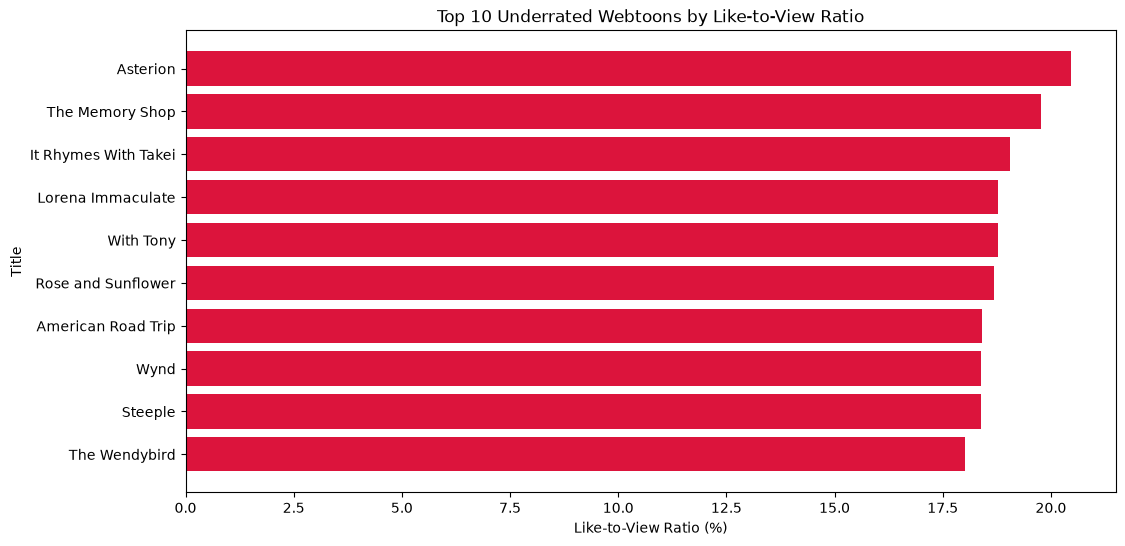

In [51]:
# cutoff for underrated: just below the median (4_908_893 milliion)

median_views = df["views"].median()
print(median_views) # prints out the median 4_908_893

# Underrated Data Frame:
underrated = lvr_df[lvr_df["views"] < median_views].head(10)
display(underrated)

# BARH PLOT : 
plt.figure(figsize = (12,6))
plt.barh(y = underrated["title"], width = underrated["lv_percent"], color="crimson")
plt.gca().invert_yaxis()

plt.title("Top 10 Underrated Webtoons by Like-to-View Ratio")
plt.xlabel("Like-to-View Ratio (%)")
plt.ylabel("Title")

plt.show()

